# scWGBS vs NOMe-HiC — per-locus HCG methylation (GM12878, hg38)

Per-CpG-site comparison of pseudobulk **HCG** (GCG-removed CpG) methylation, `smoothScatter` style of
`sc_nomehic_cellline/single_cell_vs_bulk.ipynb`, at coverage thresholds **1, 2, 3, 4, 5** (both sides).

**CpG strands merged** on the scWGBS side to match NOMe-HiC's 6plus2 convention (one entry per CpG at the
+ strand C, both strands summed). Without this the − strand cytosines (at p+1) never matched NOMe-HiC
(which folds them into p) — that had halved both the overlap and the per-site coverage.
- **x = scWGBS** pooled 2628 cells, strand-merged: `work/13_persite/wgbs_pseudobulk_HCG.cpgmerged.tsv.gz`
- **y = NOMe-HiC** pseudobulk HCG 6plus2: `gm_sc_new/pseudobulk_methylation/gm_pseudobulk_merged.HCG.6plus2.bed.gz`

In [1]:
# --- environment ---------------------------------------------------------------
# This notebook was written against the `scnome` conda environment.
#     conda env create -f env/scnome.yml && conda activate scnome
# See env/README.md for which notebook uses which environment.
.env_expected <- "scnome"
if (basename(dirname(dirname(R.home()))) != .env_expected)
  message("[env] expected the '", .env_expected, "' environment; R is from ",
          R.home(), ". See env/README.md.")

# --- repo paths: edit paths.yaml at the repository root, not this notebook ---
# Cached so that re-running this cell still works after it has setwd() away.
if (!exists(".repo_root")) {
  .r <- getwd()
  while (.r != "/" && !file.exists(file.path(.r, "paths.R"))) .r <- dirname(.r)
  stopifnot(file.exists(file.path(.r, "paths.R")))
  .repo_root <- .r
}
source(file.path(.repo_root, "paths.R"))

suppressPackageStartupMessages(library(data.table))

NOME_HCG <- file.path(WORK, "gm12878_cellline/pseudobulk_methylation/gm_pseudobulk_merged.HCG.6plus2.bed.gz")
WGBS_CPG <- file.path(WORK, "analysis/s2_new/work/13_persite/wgbs_pseudobulk_HCG.cpgmerged.tsv.gz")
FIGDIR   <- file.path(WORK, "analysis/s2_new/work/13_persite")

# scNOMe-HiC 6plus2 (one entry per CpG at + strand C): pos = end (col3), rate% col7, cov col8
nome <- fread(cmd = paste("zcat", NOME_HCG, "| grep -v '^track'"),
              header = FALSE, select = c(1, 3, 7, 8),
              col.names = c("chr", "pos", "rate", "cov_nome"))
nome[, level_nome := rate / 100]

# Drop-BS strand-merged CpG: chr, pos(=+strand C, matches NOMe end), mc, cov
wgbs <- fread(cmd = paste("zcat", WGBS_CPG), header = FALSE,
              col.names = c("chr", "pos", "mc", "cov_wgbs"))
wgbs[, level_wgbs := mc / cov_wgbs]

m <- merge(wgbs, nome, by = c("chr", "pos"))
cat(sprintf("Drop-BS CpGs: %s   scNOMe-HiC CpGs: %s   shared: %s (%.1f%% of Drop-BS)\n",
            format(nrow(wgbs), big.mark = ","), format(nrow(nome), big.mark = ","),
            format(nrow(m), big.mark = ","), 100 * nrow(m) / nrow(wgbs)))

Drop-BS CpGs: 8,976,107   scNOMe-HiC CpGs: 22,021,232   shared: 7,917,860 (88.2% of Drop-BS)


In [2]:
# correlation table across coverage thresholds
thr <- c(1, 2, 3, 4, 5)
for (t in thr) {
  s <- m[cov_wgbs >= t & cov_nome >= t]
  x <- s$level_wgbs; y <- s$level_nome
  cat(sprintf("cov >= %2d both:  n = %10s   Pearson r = %.3f   Spearman rho = %.3f\n",
              t, format(length(x), big.mark = ","), cor(x, y), cor(x, y, method = "spearman")))
}

cov >=  1 both:  n =  7,917,860   Pearson r = 0.607   Spearman rho = 0.587
cov >=  2 both:  n =  3,947,171   Pearson r = 0.661   Spearman rho = 0.636
cov >=  3 both:  n =  1,922,867   Pearson r = 0.699   Spearman rho = 0.655
cov >=  4 both:  n =  1,061,845   Pearson r = 0.715   Spearman rho = 0.644
cov >=  5 both:  n =    616,072   Pearson r = 0.722   Spearman rho = 0.617


Warning message in title(...):
“conversion failure on 'cov ≥ 1   (n = 7,917,860)' in 'mbcsToSbcs': dot substituted for <e2>”


Warning message in title(...):
“conversion failure on 'cov ≥ 1   (n = 7,917,860)' in 'mbcsToSbcs': dot substituted for <89>”


Warning message in title(...):
“conversion failure on 'cov ≥ 1   (n = 7,917,860)' in 'mbcsToSbcs': dot substituted for <a5>”


Warning message in text.default(0.04, 0.94, sprintf("r = %.3f\nρ = %.3f", r_p, :
“conversion failure on 'ρ = 0.587' in 'mbcsToSbcs': dot substituted for <cf>”


Warning message in text.default(0.04, 0.94, sprintf("r = %.3f\nρ = %.3f", r_p, :
“conversion failure on 'ρ = 0.587' in 'mbcsToSbcs': dot substituted for <81>”


Warning message in title(...):
“conversion failure on 'cov ≥ 2   (n = 3,947,171)' in 'mbcsToSbcs': dot substituted for <e2>”


... (15 outputs left out)

Warning message in title(...):
“conversion failure on 'cov ≥ 5   (n = 616,072)' in 'mbcsToSbcs': dot substituted for <89>”


Warning message in title(...):
“conversion failure on 'cov ≥ 5   (n = 616,072)' in 'mbcsToSbcs': dot substituted for <a5>”


Warning message in text.default(0.04, 0.94, sprintf("r = %.3f\nρ = %.3f", r_p, :
“conversion failure on 'ρ = 0.617' in 'mbcsToSbcs': dot substituted for <cf>”


Warning message in text.default(0.04, 0.94, sprintf("r = %.3f\nρ = %.3f", r_p, :
“conversion failure on 'ρ = 0.617' in 'mbcsToSbcs': dot substituted for <81>”


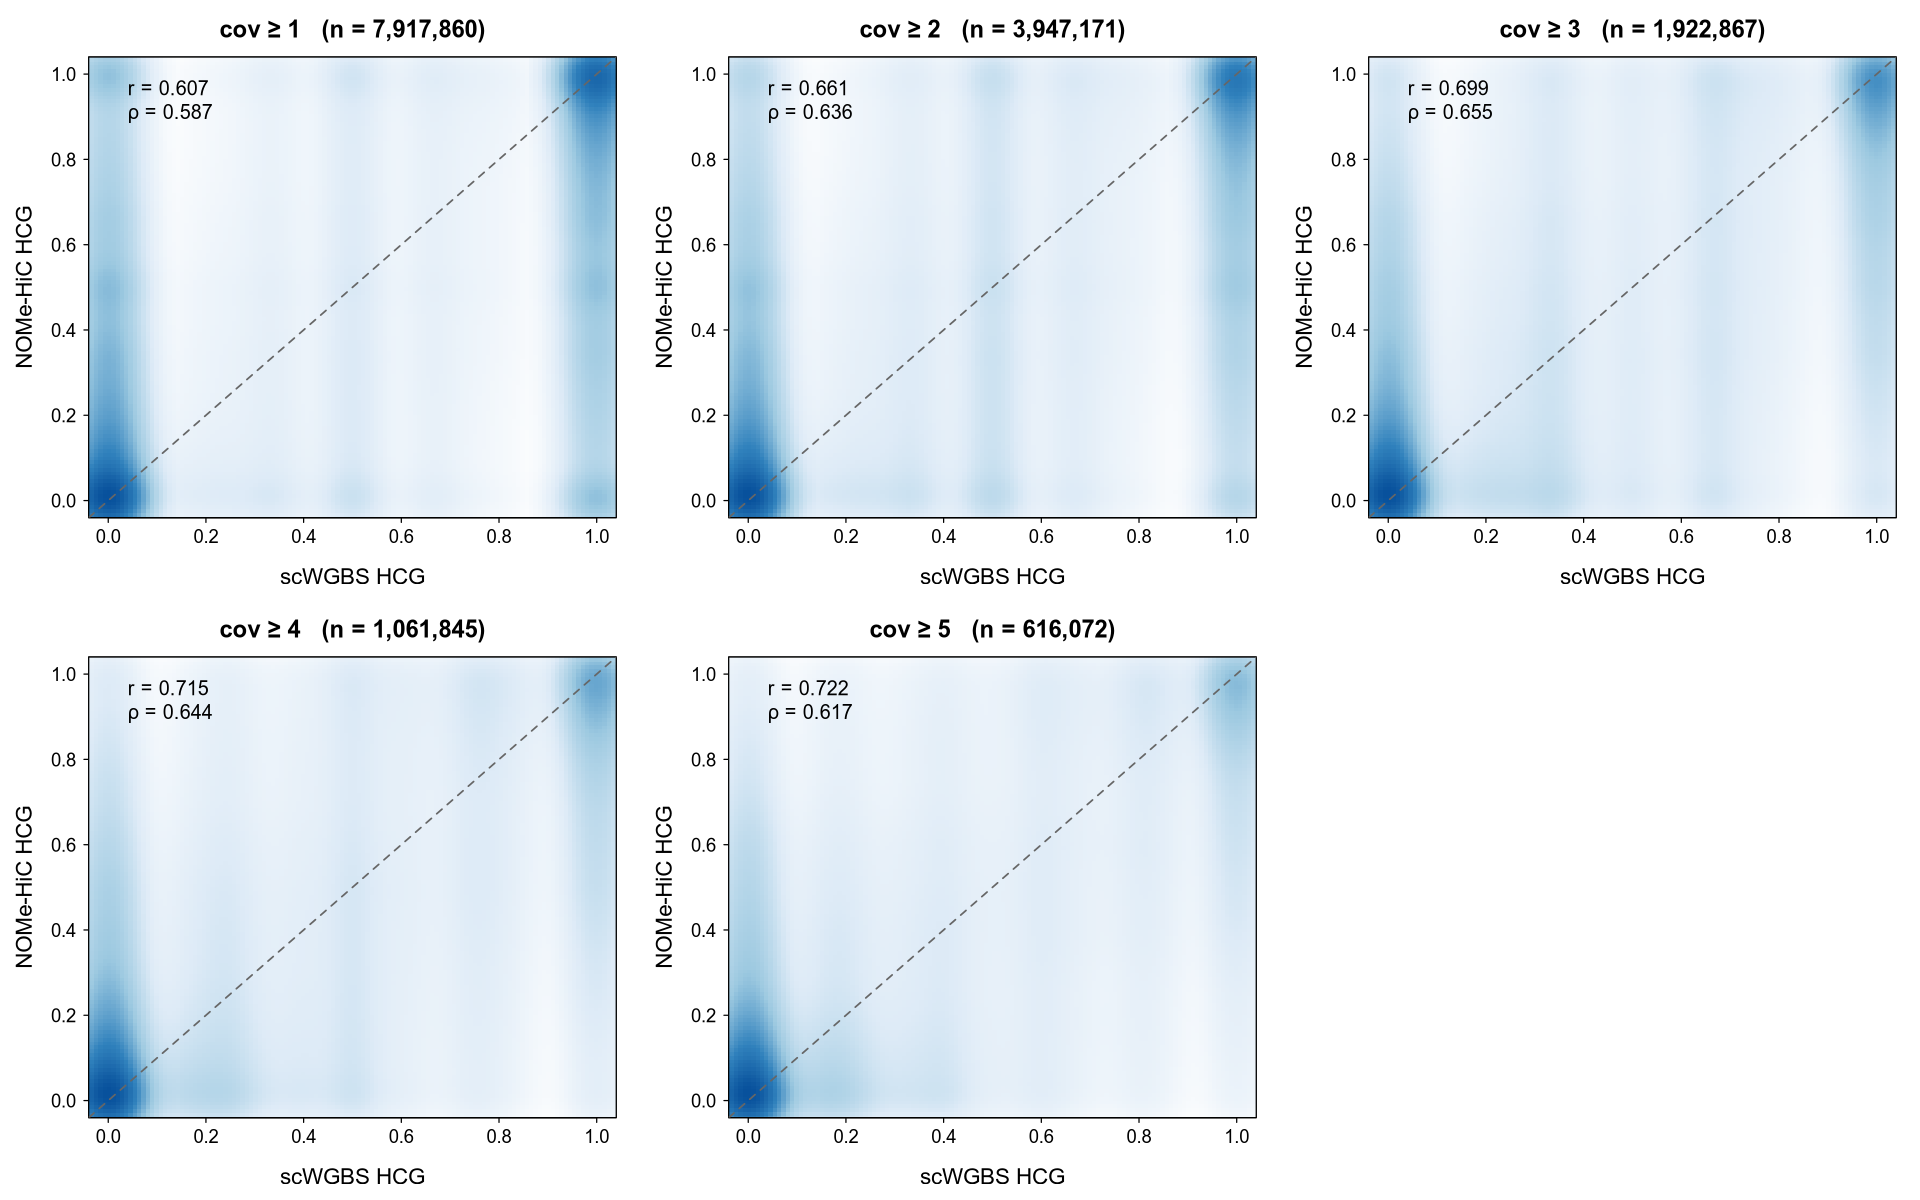

In [3]:
# 2x2 grid: per-locus HCG smoothScatter at coverage 1, 3, 5, 10 (both sides)
thr <- c(1, 2, 3, 4, 5)
bpalette <- colorRampPalette(c("white", "#deebf7", "#9ecae1", "#3182bd", "#08519c"))
draw_grid <- function() {
  par(bg = "white"); par(mfrow = c(2, 3), mar = c(5.2, 5.6, 3.6, 1.5), mgp = c(3.4, 0.8, 0),
      cex.main = 1.8, cex.lab = 1.7, cex.axis = 1.4, family = "sans", tcl = -0.3, las = 1)
  for (t in thr) {
    s <- m[cov_wgbs >= t & cov_nome >= t]
    x <- s$level_wgbs; y <- s$level_nome
    r_p <- cor(x, y); r_s <- cor(x, y, method = "spearman")
    smoothScatter(x, y, xlim = c(0, 1), ylim = c(0, 1), nrpoints = 0, colramp = bpalette,
                  xlab = "Drop-BS HCG", ylab = "scNOMe-HiC HCG",
                  main = sprintf("cov \u2265 %d   (n = %s)", t, format(length(x), big.mark = ",")))
    abline(0, 1, lty = 2, lwd = 1.4, col = "grey40")
    text(0.04, 0.94, sprintf("r = %.3f\n\u03c1 = %.3f", r_p, r_s), adj = 0, cex = 1.5)
  }
}
cairo_pdf(file.path(FIGDIR, "wgbs_vs_nomehic_persite_HCG_covgrid.pdf"), width = 16, height = 10, bg = "white"); draw_grid(); invisible(dev.off())
png(file.path(FIGDIR, "wgbs_vs_nomehic_persite_HCG_covgrid.png"), width = 3200, height = 2000, res = 200, bg = "white"); draw_grid(); invisible(dev.off())
options(repr.plot.width = 16, repr.plot.height = 10)
draw_grid()

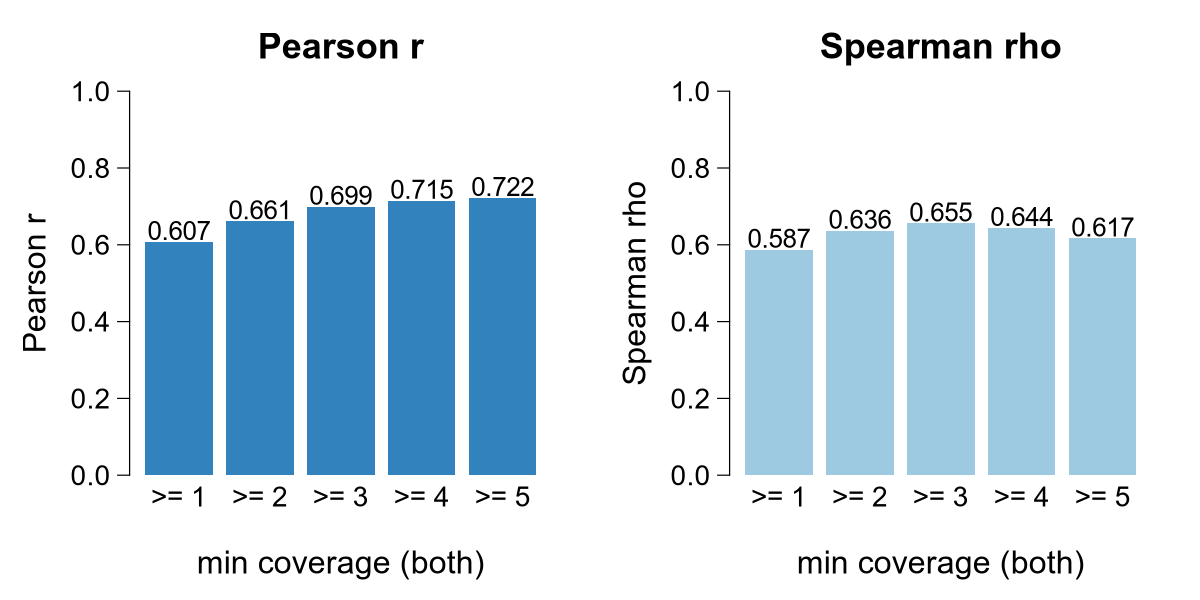

In [4]:
# Bar plots: Pearson r and Spearman rho vs coverage threshold (both sides)
thr  <- c(1, 2, 3, 4, 5)
pear <- sapply(thr, function(t){ s <- m[cov_wgbs >= t & cov_nome >= t]; cor(s$level_wgbs, s$level_nome) })
spea <- sapply(thr, function(t){ s <- m[cov_wgbs >= t & cov_nome >= t]; cor(s$level_wgbs, s$level_nome, method = "spearman") })

draw_bars <- function() {
  par(bg = "white"); par(mfrow = c(1, 2), mar = c(5.2, 5.4, 3.8, 2.0), mgp = c(3.3, 0.8, 0),
      cex.lab = 1.6, cex.axis = 1.4, cex.main = 1.8, family = "sans", las = 1)
  labs <- paste0(">= ", thr)
  one <- function(v, col, ttl, ylab) {
    # names.arg omitted; barplot auto-thins wide labels (drops '>= 10'). Draw them manually.
    b <- barplot(v, axisnames = FALSE, ylim = c(0, 1), col = col, border = NA,
                 xlab = "min coverage (both)", ylab = ylab, main = ttl)
    axis(1, at = b, labels = labs, tick = FALSE, las = 1, cex.axis = 1.4, line = -0.3)
    text(b, v + 0.03, sprintf("%.3f", v), cex = 1.3)
    invisible(b)
  }
  one(pear, "#3182bd", "Pearson r",    "Pearson r")
  one(spea, "#9ecae1", "Spearman rho", "Spearman rho")
}
pdf(file.path(FIGDIR, "wgbs_vs_nomehic_persite_HCG_corr_bars.pdf"), width = 10, height = 5, bg = "white"); draw_bars(); invisible(dev.off())
png(file.path(FIGDIR, "wgbs_vs_nomehic_persite_HCG_corr_bars.png"), width = 2000, height = 1000, res = 200, bg = "white"); draw_bars(); invisible(dev.off())
options(repr.plot.width = 10, repr.plot.height = 5)
draw_bars()

---

## sci-MET vs NOMe-HiC — per-locus HCG

Adds **sci-MET** (nbt.4112; SRR6398696 GM12878-LAND) pseudobulk per-CpG:
`work/scmet/sciMET_pseudobulk_HCG.cpgmerged.tsv.gz` (chr, pos, mc, cov; CpG strands merged via
`coverage2cytosine --merge_CpG`, then GCG removed).

*Caveat:* pooled **without per-cell demux** (the SRA deposit does not preserve the Tn5/i5 index content),
and this is the paper's first/lowest-quality prep (LAND). Mean per-CpG coverage ~3x, so high-coverage
thresholds get sparse quickly.


In [2]:
# sci-MET per-CpG (same format as the Drop-BS track): chr, pos, mc, cov
SCIMET_CPG <- file.path(WORK, "analysis/s2_new/work/scmet/sciMET_pseudobulk_HCG.cpgmerged.tsv.gz")
sci <- fread(cmd = paste("zcat", SCIMET_CPG), header = FALSE,
             col.names = c("chr", "pos", "mc", "cov_sci"))
sci[, level_sci := mc / cov_sci]

m_sci <- merge(sci, nome, by = c("chr", "pos"))
cat(sprintf("sci-MET CpGs: %s   scNOMe-HiC CpGs: %s   shared: %s (%.1f%% of sci-MET)\n",
            format(nrow(sci), big.mark = ","), format(nrow(nome), big.mark = ","),
            format(nrow(m_sci), big.mark = ","), 100 * nrow(m_sci) / nrow(sci)))

for (t in c(1, 2, 3, 4, 5)) {
  s <- m_sci[cov_sci >= t & cov_nome >= t]
  cat(sprintf("cov >= %2d both:  n = %10s   Pearson r = %.3f   Spearman rho = %.3f\n",
              t, format(nrow(s), big.mark = ","),
              cor(s$level_sci, s$level_nome), cor(s$level_sci, s$level_nome, method = "spearman")))
}

sci-MET CpGs: 9,780,201   scNOMe-HiC CpGs: 22,021,232   shared: 8,812,929 (90.1% of sci-MET)


cov >=  1 both:  n =  8,812,929   Pearson r = 0.589   Spearman rho = 0.574
cov >=  2 both:  n =  4,619,256   Pearson r = 0.649   Spearman rho = 0.636
cov >=  3 both:  n =  2,467,123   Pearson r = 0.676   Spearman rho = 0.663
cov >=  4 both:  n =  1,362,059   Pearson r = 0.689   Spearman rho = 0.673
cov >=  5 both:  n =    780,828   Pearson r = 0.689   Spearman rho = 0.670


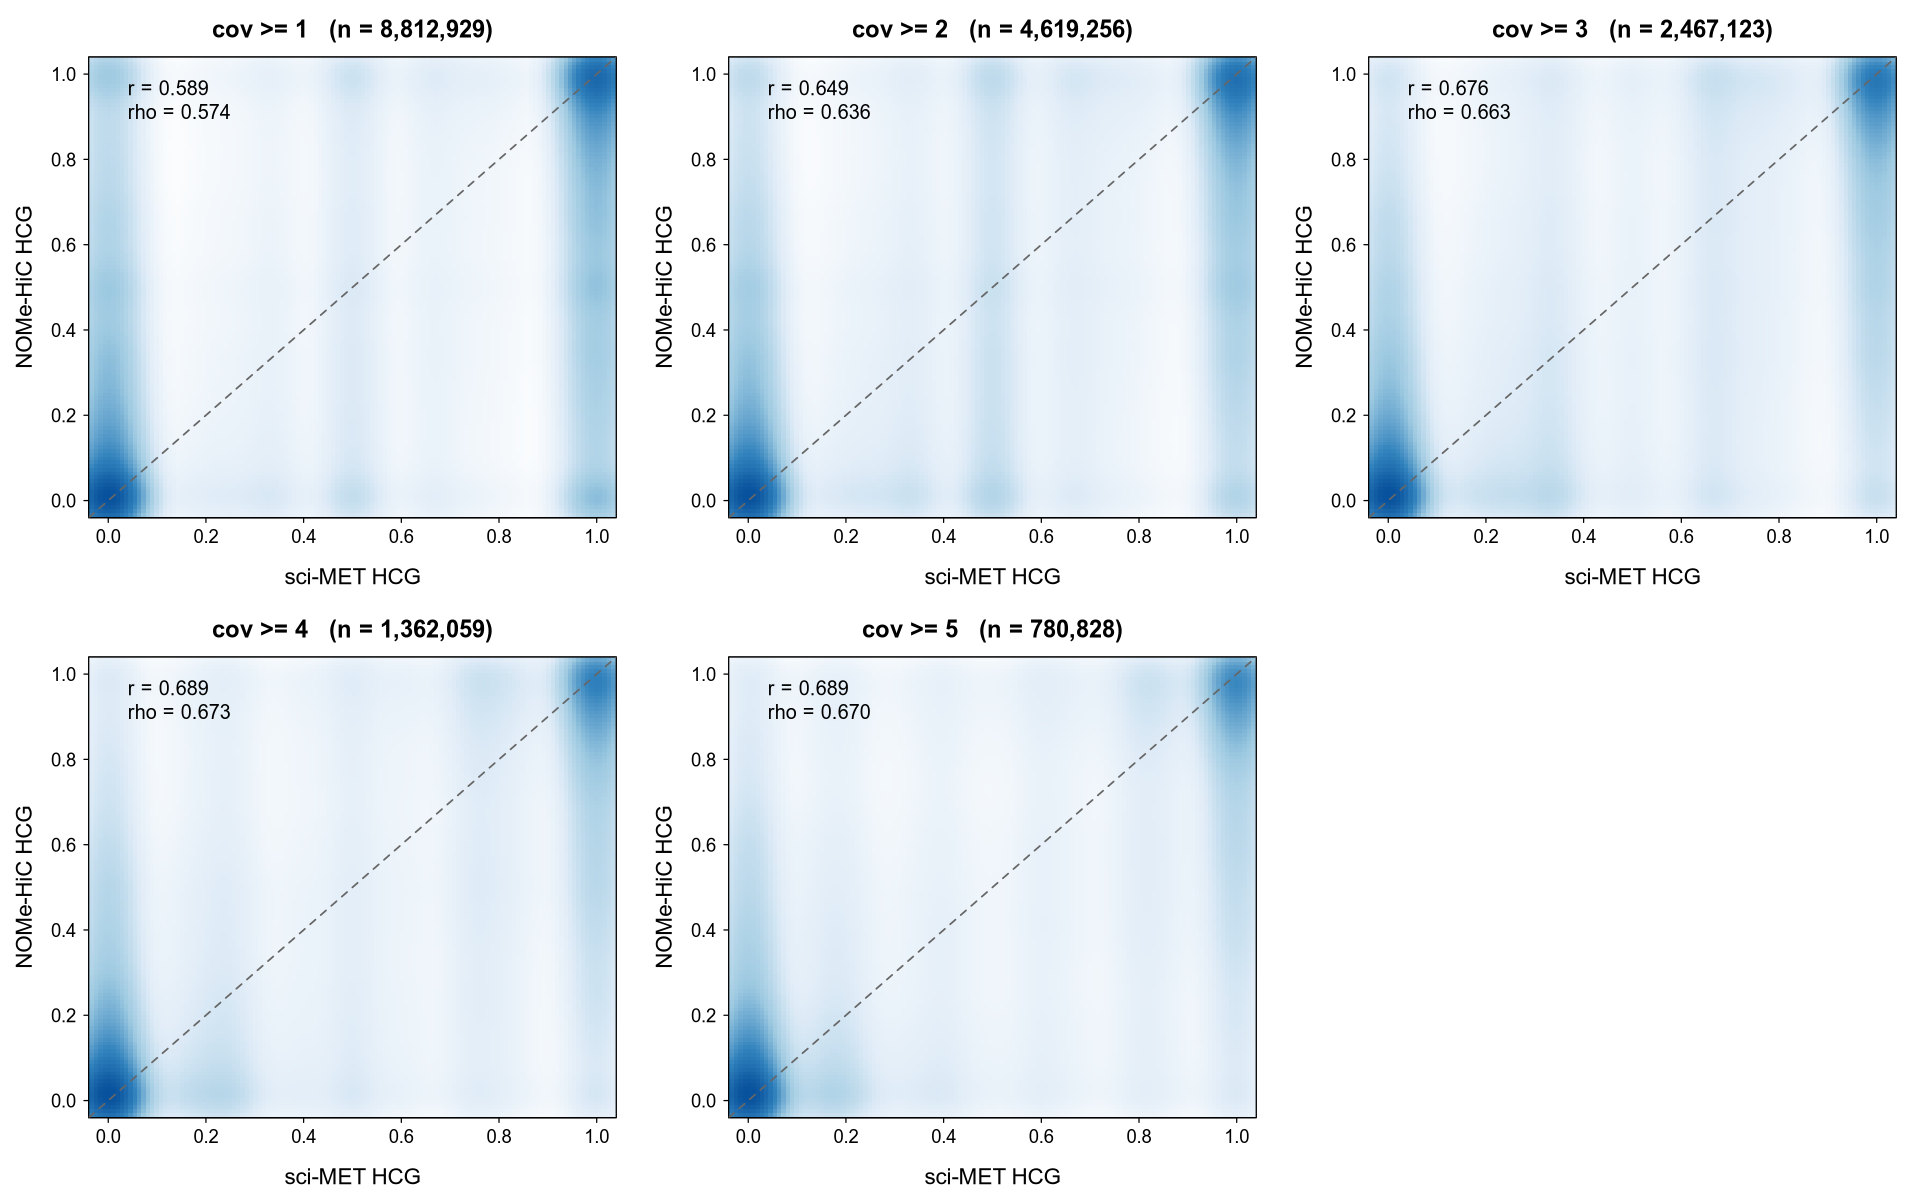

In [6]:
# 2x2 grid: sci-MET vs scNOMe-HiC per-locus HCG at coverage 1, 3, 5, 10
thr <- c(1, 2, 3, 4, 5)
bpalette <- colorRampPalette(c("white", "#deebf7", "#9ecae1", "#3182bd", "#08519c"))
draw_grid_sci <- function() {
  par(bg = "white"); par(mfrow = c(2, 3), mar = c(5.2, 5.6, 3.6, 1.5), mgp = c(3.4, 0.8, 0),
      cex.main = 1.8, cex.lab = 1.7, cex.axis = 1.4, family = "sans", tcl = -0.3, las = 1)
  for (t in thr) {
    s <- m_sci[cov_sci >= t & cov_nome >= t]
    x <- s$level_sci; y <- s$level_nome
    r_p <- cor(x, y); r_s <- cor(x, y, method = "spearman")
    smoothScatter(x, y, xlim = c(0, 1), ylim = c(0, 1), nrpoints = 0, colramp = bpalette,
                  xlab = "sci-MET HCG", ylab = "scNOMe-HiC HCG",
                  main = sprintf("cov >= %d   (n = %s)", t, format(nrow(s), big.mark = ",")))
    abline(0, 1, lty = 2, lwd = 1.4, col = "grey40")
    text(0.04, 0.94, sprintf("r = %.3f\nrho = %.3f", r_p, r_s), adj = 0, cex = 1.5)
  }
}
cairo_pdf(file.path(FIGDIR, "scimet_vs_nomehic_persite_HCG_covgrid.pdf"), width = 16, height = 10, bg = "white"); draw_grid_sci(); invisible(dev.off())
png(file.path(FIGDIR, "scimet_vs_nomehic_persite_HCG_covgrid.png"), width = 3200, height = 2000, res = 200, bg = "white"); draw_grid_sci(); invisible(dev.off())
options(repr.plot.width = 16, repr.plot.height = 10)
draw_grid_sci()

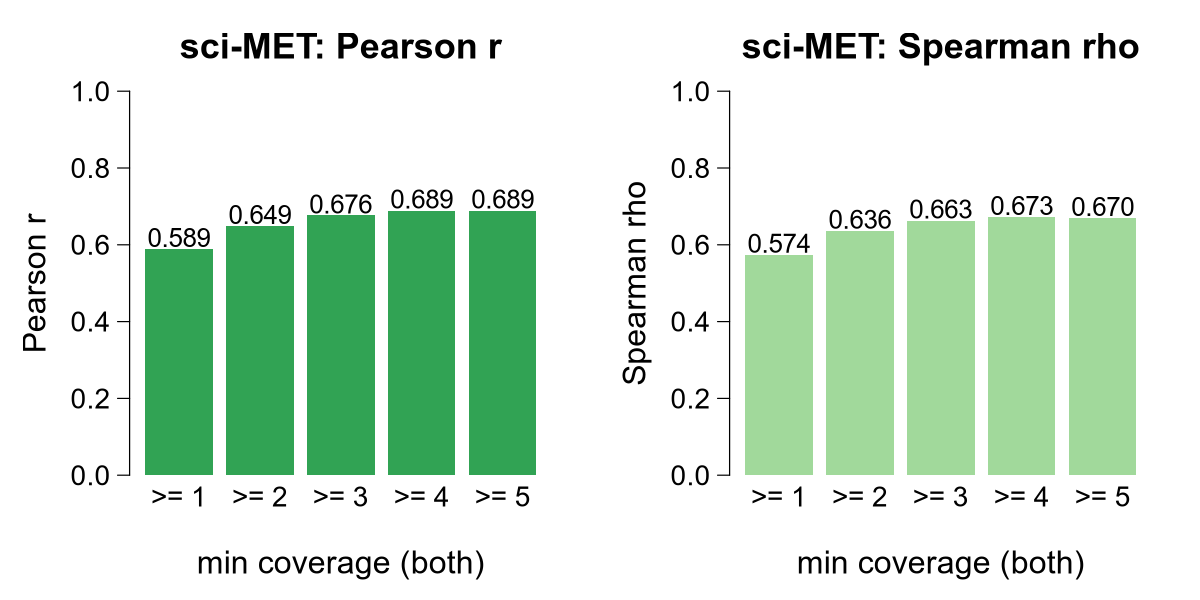

In [7]:
# Bar plots: sci-MET vs scNOMe-HiC — Pearson r and Spearman rho across coverage thresholds
thr  <- c(1, 2, 3, 4, 5)
pear_s <- sapply(thr, function(t){ s <- m_sci[cov_sci >= t & cov_nome >= t]; cor(s$level_sci, s$level_nome) })
spea_s <- sapply(thr, function(t){ s <- m_sci[cov_sci >= t & cov_nome >= t]; cor(s$level_sci, s$level_nome, method = "spearman") })
n_s    <- sapply(thr, function(t){ nrow(m_sci[cov_sci >= t & cov_nome >= t]) })

draw_bars_sci <- function() {
  par(bg = "white")
  par(mfrow = c(1, 2), mar = c(5.2, 5.4, 3.8, 2.0), mgp = c(3.3, 0.8, 0),
      cex.lab = 1.6, cex.axis = 1.4, cex.main = 1.8, family = "sans", las = 1)
  labs <- paste0(">= ", thr)
  one <- function(v, col, ttl, ylab) {
    b <- barplot(v, axisnames = FALSE, ylim = c(0, 1), col = col, border = NA,
                 xlab = "min coverage (both)", ylab = ylab, main = ttl)
    axis(1, at = b, labels = labs, tick = FALSE, las = 1, cex.axis = 1.4, line = -0.3)
    text(b, v + 0.03, sprintf("%.3f", v), cex = 1.3)
  }
  one(pear_s, "#31a354", "sci-MET: Pearson r",    "Pearson r")
  one(spea_s, "#a1d99b", "sci-MET: Spearman rho", "Spearman rho")
}
pdf(file.path(FIGDIR, "scimet_vs_nomehic_persite_HCG_corr_bars.pdf"), width = 10, height = 5, bg = "white"); draw_bars_sci(); invisible(dev.off())
png(file.path(FIGDIR, "scimet_vs_nomehic_persite_HCG_corr_bars.png"), width = 2000, height = 1000, res = 200, bg = "white"); draw_bars_sci(); invisible(dev.off())
options(repr.plot.width = 10, repr.plot.height = 5)
draw_bars_sci()

---

## Both platforms vs NOMe-HiC, side by side

Grouped bars: **Drop-BS vs NOMe-HiC** and **sci-MET vs NOMe-HiC** at each coverage threshold, so the two
single-cell methylation platforms can be compared directly against the same NOMe-HiC reference.


n per threshold (Drop-BS / sci-MET):


  cov >=  1 :  7,917,860 /  8,812,929
  cov >=  2 :  3,947,171 /  4,619,256
  cov >=  3 :  1,922,867 /  2,467,123
  cov >=  4 :  1,061,845 /  1,362,059
  cov >=  5 :    616,072 /    780,828


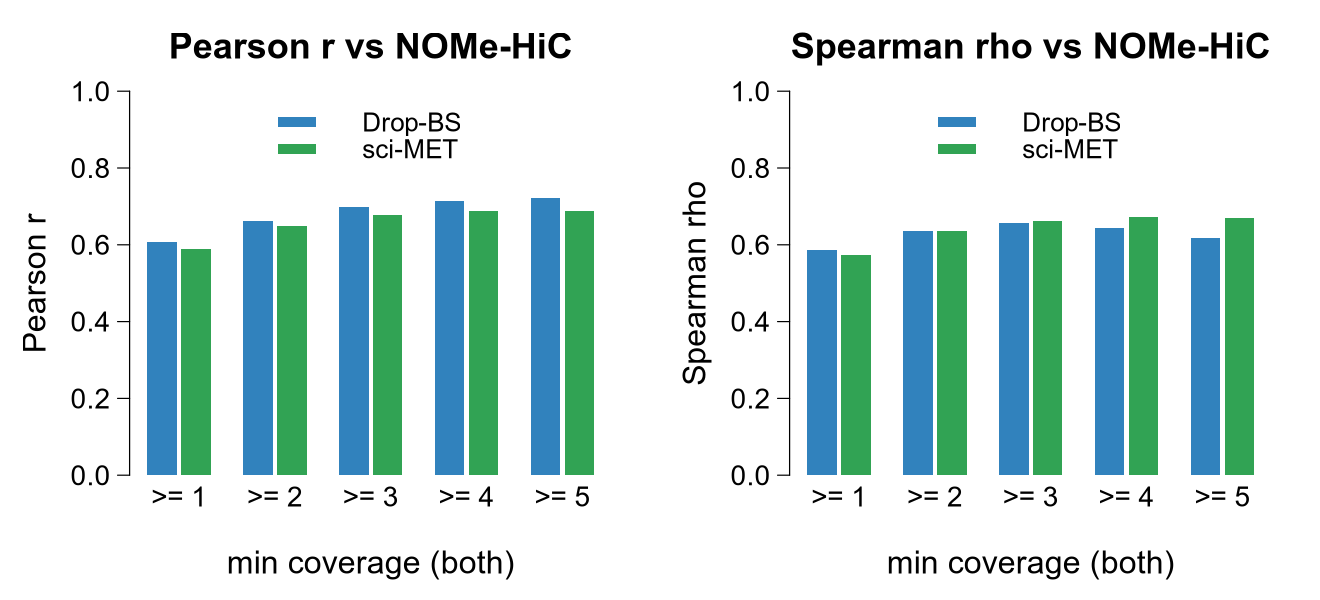

In [8]:
# Combined: Drop-BS vs scNOMe-HiC  AND  sci-MET vs scNOMe-HiC, grouped by coverage threshold
pear_w <- sapply(thr, function(t){ s <- m[cov_wgbs >= t & cov_nome >= t]; cor(s$level_wgbs, s$level_nome) })
spea_w <- sapply(thr, function(t){ s <- m[cov_wgbs >= t & cov_nome >= t]; cor(s$level_wgbs, s$level_nome, method = "spearman") })
n_w    <- sapply(thr, function(t){ nrow(m[cov_wgbs >= t & cov_nome >= t]) })

P <- rbind(`Drop-BS` = pear_w, `sci-MET` = pear_s)
S <- rbind(`Drop-BS` = spea_w, `sci-MET` = spea_s)
colnames(P) <- paste0(">= ", thr); colnames(S) <- paste0(">= ", thr)
cat("n per threshold (Drop-BS / sci-MET):\n")
for (i in seq_along(thr)) cat(sprintf("  cov >= %2d : %10s / %10s\n", thr[i],
    format(n_w[i], big.mark=","), format(n_s[i], big.mark=",")))

COLS <- c("#3182bd", "#31a354")
draw_combined <- function() {
  par(bg = "white")
  par(mfrow = c(1, 2), mar = c(5.2, 5.4, 3.8, 2.0), mgp = c(3.3, 0.8, 0),
      cex.lab = 1.6, cex.axis = 1.4, cex.main = 1.8, family = "sans", las = 1)
  one <- function(M, ttl, ylab) {
    # space = c(within-group, between-group): clear gaps between coverage groups
    b <- barplot(M, beside = TRUE, ylim = c(0, 1), col = COLS, border = NA,
                 space = c(0.15, 1.1), axisnames = FALSE,
                 xlab = "min coverage (both)", ylab = ylab, main = ttl)
    axis(1, at = colMeans(b), labels = colnames(M), tick = FALSE, las = 1,
         cex.axis = 1.4, line = -0.3)
    legend("topright", legend = rownames(M), fill = COLS, border = NA,
           bty = "n", cex = 1.3, y.intersp = 1.4, inset = c(0.02, 0.02))
  }
  one(P, "Pearson r vs scNOMe-HiC",    "Pearson r")
  one(S, "Spearman rho vs scNOMe-HiC", "Spearman rho")
}
pdf(file.path(FIGDIR, "both_vs_nomehic_persite_corr_bars.pdf"), width = 11, height = 5, bg = "white"); draw_combined(); invisible(dev.off())
png(file.path(FIGDIR, "both_vs_nomehic_persite_corr_bars.png"), width = 2200, height = 1000, res = 200, bg = "white"); draw_combined(); invisible(dev.off())
options(repr.plot.width = 11, repr.plot.height = 5)
draw_combined()

---

## sci-MET vs scWGBS — per-locus HCG (no NOMe-HiC)

The third pairwise comparison: the two external single-cell methylation platforms against **each other**,
at the same coverage thresholds **1, 2, 3, 4, 5**. Neither track involves NOMe-HiC, so this measures how
well two independent single-cell methylation assays agree on GM12878 — an upper bound on what any
platform-vs-platform per-locus correlation can look like here.

*Caveat:* both tracks were built by the **same** in-house code (GCG removal + strand merge), so this
agreement is not fully independent of my processing choices. The sci-MET track is also still pooled
without per-cell demux (see above).


In [3]:
# sci-MET vs Drop-BS: merge the two external platforms directly (no scNOMe-HiC)
m_sw <- merge(sci, wgbs, by = c("chr", "pos"))
cat(sprintf("sci-MET CpGs: %s   Drop-BS CpGs: %s   shared: %s (%.1f%% of sci-MET, %.1f%% of Drop-BS)\n",
            format(nrow(sci), big.mark = ","), format(nrow(wgbs), big.mark = ","),
            format(nrow(m_sw), big.mark = ","),
            100 * nrow(m_sw) / nrow(sci), 100 * nrow(m_sw) / nrow(wgbs)))

thr <- c(1, 2, 3, 4, 5)
for (t in thr) {
  s <- m_sw[cov_sci >= t & cov_wgbs >= t]
  cat(sprintf("cov >= %2d both:  n = %10s   Pearson r = %.3f   Spearman rho = %.3f\n",
              t, format(nrow(s), big.mark = ","),
              cor(s$level_sci, s$level_wgbs), cor(s$level_sci, s$level_wgbs, method = "spearman")))
}

sci-MET CpGs: 9,780,201   Drop-BS CpGs: 8,976,107   shared: 4,329,097 (44.3% of sci-MET, 48.2% of Drop-BS)


cov >=  1 both:  n =  4,329,097   Pearson r = 0.595   Spearman rho = 0.586
cov >=  2 both:  n =  1,577,098   Pearson r = 0.688   Spearman rho = 0.670
cov >=  3 both:  n =    598,326   Pearson r = 0.744   Spearman rho = 0.694
cov >=  4 both:  n =    257,594   Pearson r = 0.763   Spearman rho = 0.663
cov >=  5 both:  n =    118,913   Pearson r = 0.762   Spearman rho = 0.607


Warning message in title(...):
“conversion failure on 'cov ≥ 1   (n = 4,329,097)' in 'mbcsToSbcs': dot substituted for <e2>”


Warning message in title(...):
“conversion failure on 'cov ≥ 1   (n = 4,329,097)' in 'mbcsToSbcs': dot substituted for <89>”


Warning message in title(...):
“conversion failure on 'cov ≥ 1   (n = 4,329,097)' in 'mbcsToSbcs': dot substituted for <a5>”


Warning message in text.default(0.04, 0.94, sprintf("r = %.3f\nρ = %.3f", r_p, :
“conversion failure on 'ρ = 0.586' in 'mbcsToSbcs': dot substituted for <cf>”


Warning message in text.default(0.04, 0.94, sprintf("r = %.3f\nρ = %.3f", r_p, :
“conversion failure on 'ρ = 0.586' in 'mbcsToSbcs': dot substituted for <81>”


Warning message in title(...):
“conversion failure on 'cov ≥ 2   (n = 1,577,098)' in 'mbcsToSbcs': dot substituted for <e2>”


... (15 outputs left out)

Warning message in title(...):
“conversion failure on 'cov ≥ 5   (n = 118,913)' in 'mbcsToSbcs': dot substituted for <89>”


Warning message in title(...):
“conversion failure on 'cov ≥ 5   (n = 118,913)' in 'mbcsToSbcs': dot substituted for <a5>”


Warning message in text.default(0.04, 0.94, sprintf("r = %.3f\nρ = %.3f", r_p, :
“conversion failure on 'ρ = 0.607' in 'mbcsToSbcs': dot substituted for <cf>”


Warning message in text.default(0.04, 0.94, sprintf("r = %.3f\nρ = %.3f", r_p, :
“conversion failure on 'ρ = 0.607' in 'mbcsToSbcs': dot substituted for <81>”


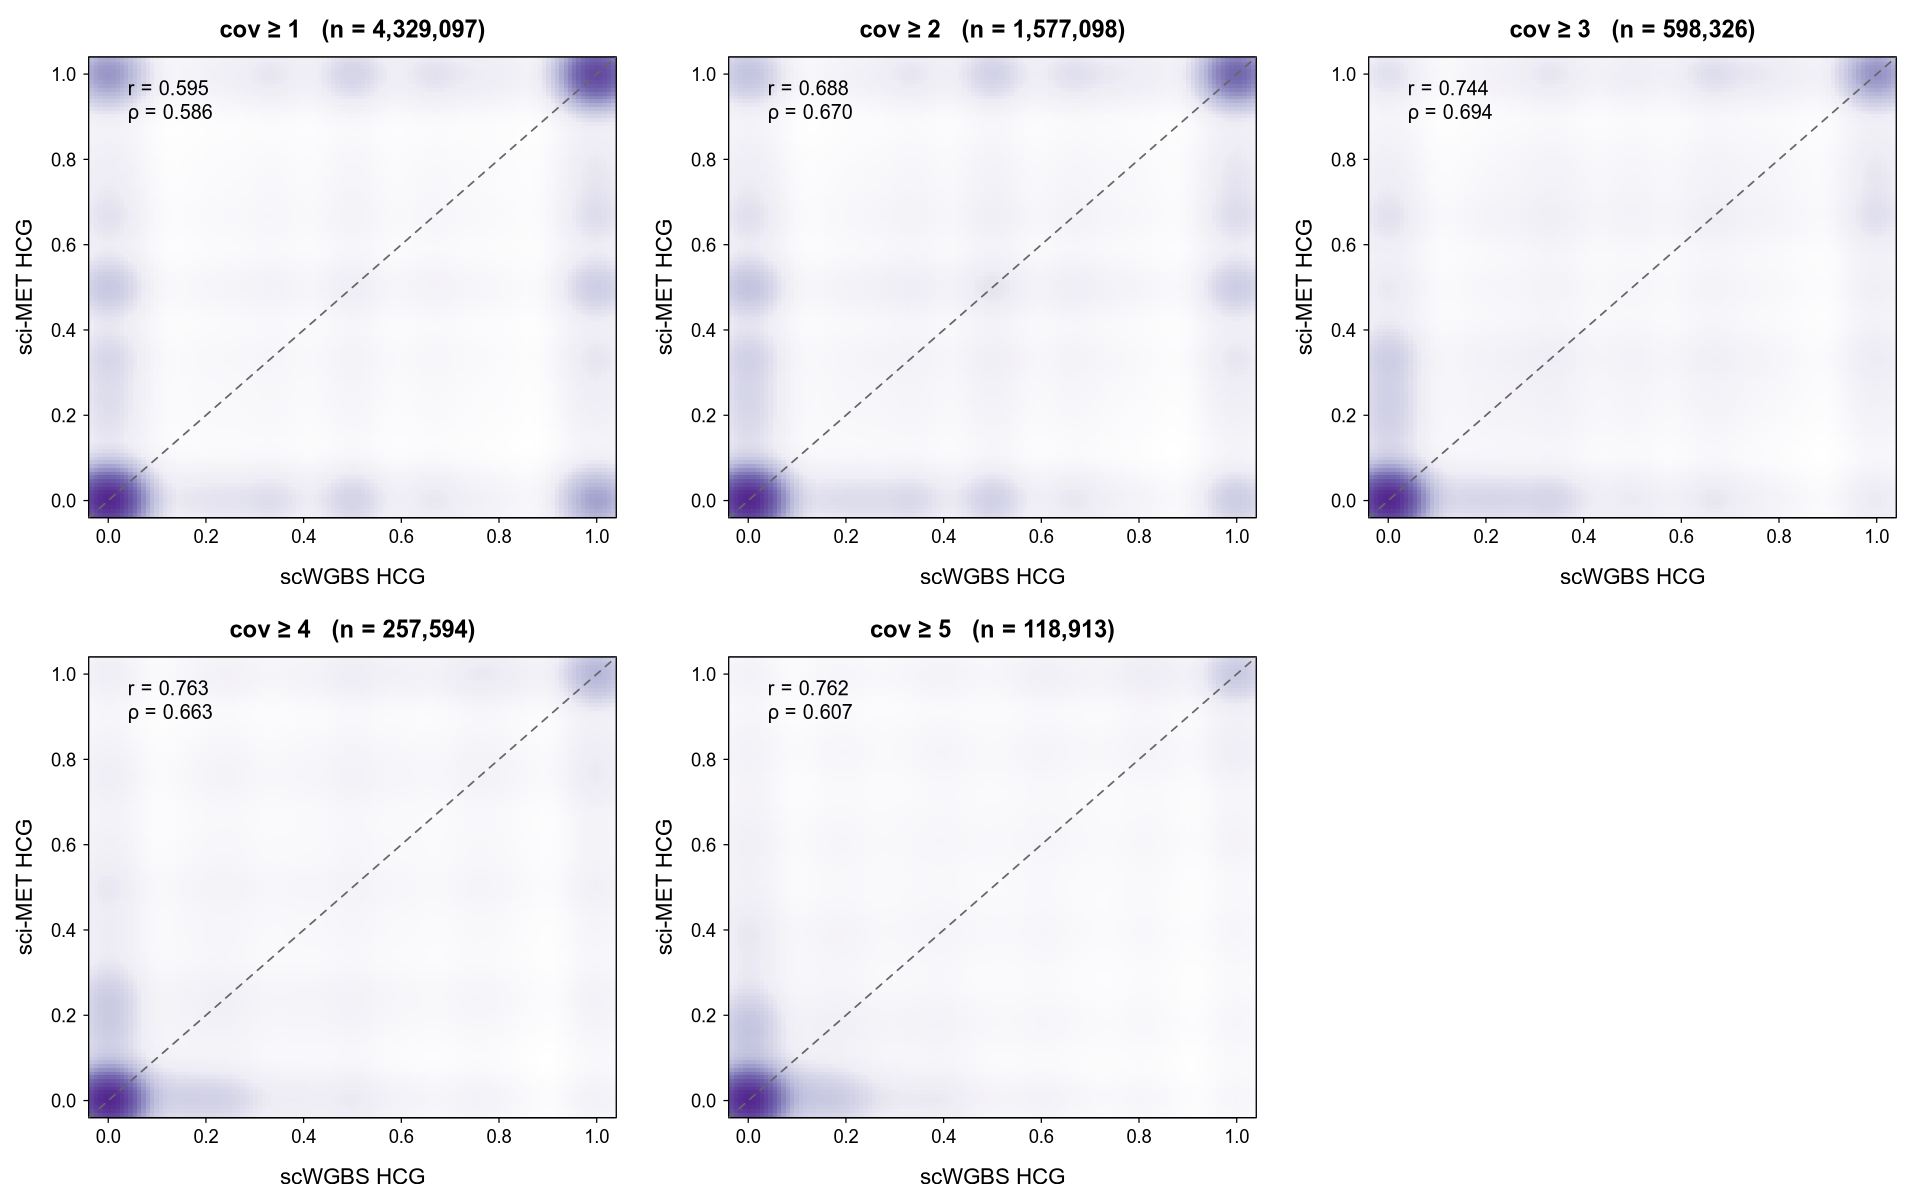

In [10]:
# 2x3 grid: sci-MET vs Drop-BS per-locus HCG smoothScatter at coverage 1,2,3,4,5 (both sides)
thr <- c(1, 2, 3, 4, 5)
ppalette <- colorRampPalette(c("white", "#efedf5", "#bcbddc", "#756bb1", "#54278f"))
draw_grid_sw <- function() {
  par(bg = "white"); par(mfrow = c(2, 3), mar = c(5.2, 5.6, 3.6, 1.5), mgp = c(3.4, 0.8, 0),
      cex.main = 1.8, cex.lab = 1.7, cex.axis = 1.4, family = "sans", tcl = -0.3, las = 1)
  for (t in thr) {
    s <- m_sw[cov_sci >= t & cov_wgbs >= t]
    x <- s$level_wgbs; y <- s$level_sci
    r_p <- cor(x, y); r_s <- cor(x, y, method = "spearman")
    smoothScatter(x, y, xlim = c(0, 1), ylim = c(0, 1), nrpoints = 0, colramp = ppalette,
                  xlab = "Drop-BS HCG", ylab = "sci-MET HCG",
                  main = sprintf("cov \u2265 %d   (n = %s)", t, format(nrow(s), big.mark = ",")))
    abline(0, 1, lty = 2, lwd = 1.4, col = "grey40")
    text(0.04, 0.94, sprintf("r = %.3f\n\u03c1 = %.3f", r_p, r_s), adj = 0, cex = 1.5)
  }
}
cairo_pdf(file.path(FIGDIR, "scimet_vs_wgbs_persite_HCG_covgrid.pdf"), width = 16, height = 10, bg = "white"); draw_grid_sw(); invisible(dev.off())
png(file.path(FIGDIR, "scimet_vs_wgbs_persite_HCG_covgrid.png"), width = 3200, height = 2000, res = 200, bg = "white"); draw_grid_sw(); invisible(dev.off())
options(repr.plot.width = 16, repr.plot.height = 10)
draw_grid_sw()

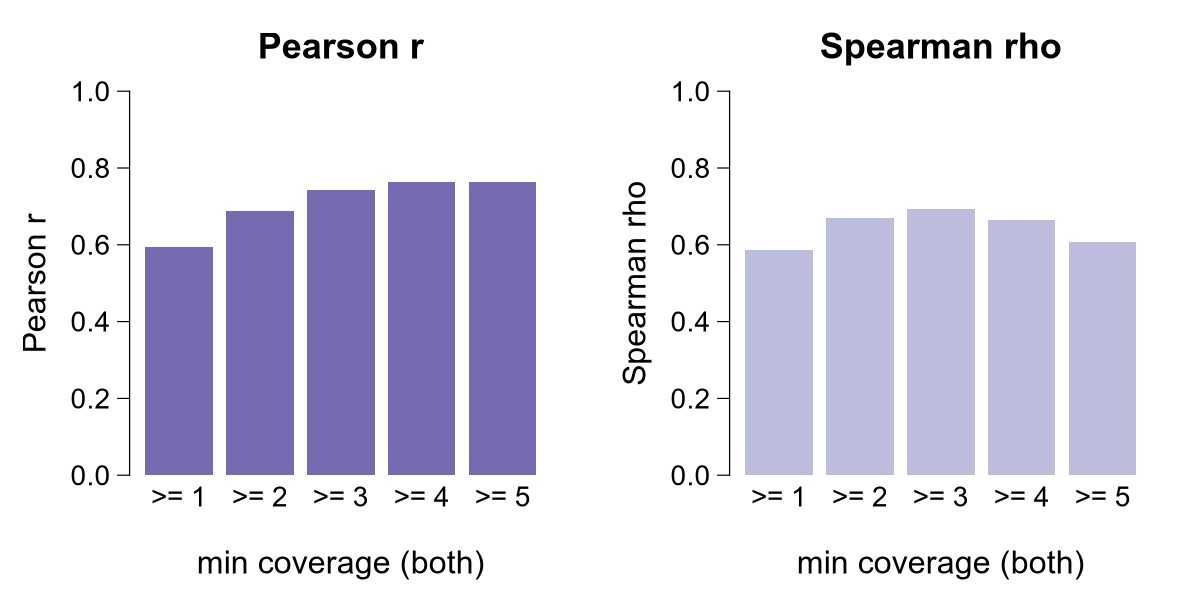

In [11]:
# Bar plots: sci-MET vs Drop-BS Pearson r and Spearman rho vs coverage threshold
thr     <- c(1, 2, 3, 4, 5)
pear_sw <- sapply(thr, function(t){ s <- m_sw[cov_sci >= t & cov_wgbs >= t]; cor(s$level_sci, s$level_wgbs) })
spea_sw <- sapply(thr, function(t){ s <- m_sw[cov_sci >= t & cov_wgbs >= t]; cor(s$level_sci, s$level_wgbs, method = "spearman") })

draw_bars_sw <- function() {
  par(bg = "white"); par(mfrow = c(1, 2), mar = c(5.2, 5.4, 3.8, 2.0), mgp = c(3.3, 0.8, 0),
      cex.lab = 1.6, cex.axis = 1.4, cex.main = 1.8, family = "sans", las = 1)
  labs <- paste0(">= ", thr)
  one <- function(v, col, ttl, ylab) {
    b <- barplot(v, axisnames = FALSE, ylim = c(0, 1), col = col, border = NA,
                 xlab = "min coverage (both)", ylab = ylab, main = ttl)
    axis(1, at = b, labels = labs, tick = FALSE, las = 1, cex.axis = 1.4, line = -0.3)
    invisible(b)
  }
  one(pear_sw, "#756bb1", "Pearson r",    "Pearson r")
  one(spea_sw, "#bcbddc", "Spearman rho", "Spearman rho")
}
pdf(file.path(FIGDIR, "scimet_vs_wgbs_persite_HCG_corr_bars.pdf"), width = 10, height = 5, bg = "white"); draw_bars_sw(); invisible(dev.off())
png(file.path(FIGDIR, "scimet_vs_wgbs_persite_HCG_corr_bars.png"), width = 2000, height = 1000, res = 200, bg = "white"); draw_bars_sw(); invisible(dev.off())
options(repr.plot.width = 10, repr.plot.height = 5)
draw_bars_sw()

---

## All three pairwise comparisons together — thresholds 1, 2, 3

Grouped bars with **three** series per coverage threshold:

- **Drop-BS vs NOMe-HiC** (blue)
- **sci-MET vs NOMe-HiC** (green)
- **sci-MET vs scWGBS** (purple) — the two external platforms against each other

Restricted to **cov >= 1, 2, 3**, where every pair still retains a large number of shared
sites (the >=4 / >=5 bins thin out fastest for the sci-MET vs scWGBS pair, which starts from
a much smaller intersection: 4.3M sites vs ~8-9M for the NOMe-HiC pairs).

*Note:* the n per bar differs between the three pairs — each is the intersection of a
different pair of tracks, not a common site set. The bars compare correlation, not coverage.


Pearson r:


                       >= 1  >= 2  >= 3
Drop-BS vs scNOMe-HiC 0.607 0.661 0.699
sci-MET vs scNOMe-HiC 0.589 0.649 0.676
sci-MET vs Drop-BS    0.595 0.688 0.744



Spearman rho:


                       >= 1  >= 2  >= 3
Drop-BS vs scNOMe-HiC 0.587 0.636 0.655
sci-MET vs scNOMe-HiC 0.574 0.636 0.663
sci-MET vs Drop-BS    0.586 0.670 0.694



n sites per bar:


                      >= 1      >= 2      >= 3     
Drop-BS vs scNOMe-HiC 7,917,860 3,947,171 1,922,867
sci-MET vs scNOMe-HiC 8,812,929 4,619,256 2,467,123
sci-MET vs Drop-BS    4,329,097 1,577,098 598,326  


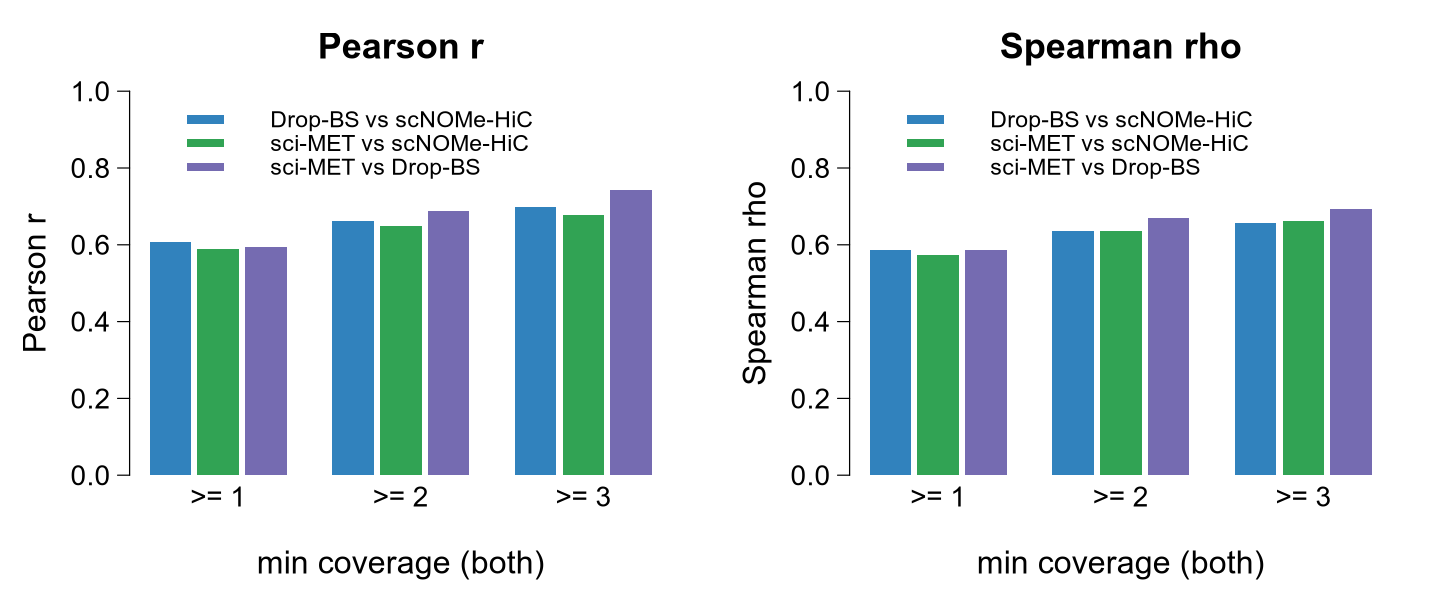

In [4]:
# Three-way grouped barplot: all pairwise comparisons at cov >= 1, 2, 3
thr3 <- c(1, 2, 3)

# recompute explicitly (do not subset the length-5 vectors) so this cell stands alone
pear3 <- rbind(
  `Drop-BS vs scNOMe-HiC` = sapply(thr3, function(t){ s <- m[cov_wgbs >= t & cov_nome >= t];     cor(s$level_wgbs, s$level_nome) }),
  `sci-MET vs scNOMe-HiC` = sapply(thr3, function(t){ s <- m_sci[cov_sci >= t & cov_nome >= t];  cor(s$level_sci,  s$level_nome) }),
  `sci-MET vs Drop-BS`   = sapply(thr3, function(t){ s <- m_sw[cov_sci >= t & cov_wgbs >= t];   cor(s$level_sci,  s$level_wgbs) })
)
spea3 <- rbind(
  `Drop-BS vs scNOMe-HiC` = sapply(thr3, function(t){ s <- m[cov_wgbs >= t & cov_nome >= t];     cor(s$level_wgbs, s$level_nome, method = "spearman") }),
  `sci-MET vs scNOMe-HiC` = sapply(thr3, function(t){ s <- m_sci[cov_sci >= t & cov_nome >= t];  cor(s$level_sci,  s$level_nome, method = "spearman") }),
  `sci-MET vs Drop-BS`   = sapply(thr3, function(t){ s <- m_sw[cov_sci >= t & cov_wgbs >= t];   cor(s$level_sci,  s$level_wgbs, method = "spearman") })
)
n3 <- rbind(
  `Drop-BS vs scNOMe-HiC` = sapply(thr3, function(t) nrow(m[cov_wgbs >= t & cov_nome >= t])),
  `sci-MET vs scNOMe-HiC` = sapply(thr3, function(t) nrow(m_sci[cov_sci >= t & cov_nome >= t])),
  `sci-MET vs Drop-BS`   = sapply(thr3, function(t) nrow(m_sw[cov_sci >= t & cov_wgbs >= t]))
)
colnames(pear3) <- paste0(">= ", thr3); colnames(spea3) <- paste0(">= ", thr3)
colnames(n3) <- paste0(">= ", thr3)

cat("Pearson r:\n");      print(round(pear3, 3))
cat("\nSpearman rho:\n"); print(round(spea3, 3))
cat("\nn sites per bar:\n")
print(apply(n3, c(1, 2), function(v) format(v, big.mark = ",")), quote = FALSE)

COLS3 <- c("#3182bd", "#31a354", "#756bb1")
draw_three <- function() {
  par(bg = "white")
  par(mfrow = c(1, 2), mar = c(5.2, 5.4, 3.8, 2.0), mgp = c(3.3, 0.8, 0),
      cex.lab = 1.6, cex.axis = 1.4, cex.main = 1.8, family = "sans", las = 1)
  one <- function(M, ttl, ylab) {
    # space = c(within-group, between-group); axisnames=FALSE so axis() below draws labels
    b <- barplot(M, beside = TRUE, ylim = c(0, 1), col = COLS3, border = NA,
                 space = c(0.15, 1.1), axisnames = FALSE,
                 xlab = "min coverage (both)", ylab = ylab, main = ttl)
    axis(1, at = colMeans(b), labels = colnames(M), tick = FALSE, las = 1,
         cex.axis = 1.4, line = -0.3)
    legend("topleft", legend = rownames(M), fill = COLS3, border = NA,
           bty = "n", cex = 1.15, y.intersp = 1.4, inset = c(0.02, 0.02))
  }
  one(pear3, "Pearson r",    "Pearson r")
  one(spea3, "Spearman rho", "Spearman rho")
}
pdf(file.path(FIGDIR, "three_way_persite_corr_bars.pdf"), width = 12, height = 5, bg = "white"); draw_three(); invisible(dev.off())
png(file.path(FIGDIR, "three_way_persite_corr_bars.png"), width = 2400, height = 1000, res = 200, bg = "white"); draw_three(); invisible(dev.off())
options(repr.plot.width = 12, repr.plot.height = 5)
draw_three()